# Puzzle World - Tahap 1: Puzzle Generator
Input: 1 gambar (RGB / grayscale) + parameter `M` (grid M x M).  
Bingkai = **gambar asli itu sendiri** dengan bagian tengahnya dikosongkan (berkontur grid). Potongan puzzle diambil dari bagian tengah yang dikosongkan itu, jadi ukurannya pas dengan lubang bingkai.  
Output: 1 berkas bingkai + N = M x M berkas potongan (di-shuffle dan di-rotate) + `info.json` sebagai kunci jawaban.

## 1. Setup dan parameter

In [1]:
import io
import json
import math
import os
import urllib.request

import numpy as np
import matplotlib.pyplot as plt
from PIL import Image

# ---- Parameter (ubah di sini) ----
IMAGE_SOURCE = "https://encrypted-tbn0.gstatic.com/images?q=tbn:ANd9GcRfukVlyVmsM27gQbW-YfHLOSw740iO84r7NJLKb6RCgRxqYiChrwTlxKk-&s=10"   # URL gambar, atau path file lokal (mis. "gambar.png")
M = 3                                      # jumlah potongan per sisi -> N = M x M
FRAME_BORDER = 0.12                        # tebal minimal bingkai, sebagai pecahan dari sisi terpendek gambar
OUT_DIR = "puzzle_output"                  # folder tempat berkas output disimpan
SHUFFLE = True                             # acak urutan potongan (nama berkas tidak membocorkan posisi)
ROTATE = True                              # putar acak tiap potongan: 0 / 90 / 180 / 270 derajat
SEED = None                               # supaya hasil acak bisa diulang

## 2. Membaca citra

In [2]:
def load_image(source):
    """Baca gambar dari URL atau path lokal.
    Hasil: array uint8 (H, W) untuk grayscale atau (H, W, 3) untuk RGB."""
    if source.startswith(("http://", "https://")):
        req = urllib.request.Request(source, headers={"User-Agent": "Mozilla/5.0"})
        data = urllib.request.urlopen(req, timeout=15).read()
        im = Image.open(io.BytesIO(data))
    else:
        im = Image.open(source)

    # Pertahankan grayscale bila memang grayscale; selain itu jadikan RGB (juga membuang alpha/palette)
    im = im.convert("L") if im.mode in ("L", "1", "I", "I;16", "F") else im.convert("RGB")
    return np.array(im, dtype=np.uint8)

## 3. Menentukan lubang bingkai (area potongan)

In [3]:
def compute_hole(H, W, M, border_frac=0.12):
    """Tentukan area persegi di tengah gambar yang akan dikosongkan (lubang bingkai).
    Sisanya tetap berisi gambar asli dan menjadi bingkai. Tiap sel berbentuk persegi sisi s,
    sehingga potongan tetap pas di lubang walau diputar 90 derajat.
    Mengembalikan (top, left, s) dengan ukuran lubang = s*M."""
    b = max(2, int(round(border_frac * min(H, W))))   # tebal minimal bingkai
    s = min(H - 2 * b, W - 2 * b) // M                # sisi satu sel/potongan
    if s < 4:
        raise ValueError(f"M={M} terlalu besar untuk gambar {W}x{H}. Kecilkan M atau FRAME_BORDER.")
    L = s * M
    return (H - L) // 2, (W - L) // 2, s

## 4. Membuat bingkai (frame)

In [4]:
def make_frame(img, top, left, s, M, thickness=2, bg=235, line=40):
    """Bingkai = gambar asli dengan area lubang dikosongkan (abu terang), lalu digambari
    garis grid M x M dan kontur lubang sebagai acuan penyusunan. Ukuran/rasio sama dengan gambar."""
    L = s * M
    frame = img.copy()
    frame[top:top + L, left:left + L] = bg            # kosongkan lubang (berlaku untuk RGB maupun grayscale)

    # Garis grid antar sel
    for i in range(1, M):
        y, x = top + i * s, left + i * s
        frame[y - thickness // 2: y + (thickness + 1) // 2, left:left + L] = line
        frame[top:top + L, x - thickness // 2: x + (thickness + 1) // 2] = line

    # Kontur lubang (sedikit lebih tebal, digambar di sisi dalam lubang)
    t = thickness + 1
    frame[top:top + t, left:left + L] = line
    frame[top + L - t:top + L, left:left + L] = line
    frame[top:top + L, left:left + t] = line
    frame[top:top + L, left + L - t:left + L] = line
    return frame

## 5. Memotong gambar menjadi N potongan

In [5]:
def split_into_pieces(img, top, left, s, M):
    """Potong area lubang menjadi M x M potongan persegi (sisi s), urutan baris demi baris.
    Mengembalikan list of (potongan, baris, kolom)."""
    pieces = []
    for r in range(M):
        for c in range(M):
            y, x = top + r * s, left + c * s
            pieces.append((img[y:y + s, x:x + s].copy(), r, c))
    return pieces

## 6. Shuffle dan rotasi acak

In [6]:
def rotate90(img, k):
    """Putar k x 90 derajat berlawanan arah jarum jam: transpose lalu flip baris."""
    for _ in range(k % 4):
        img = img.swapaxes(0, 1)[::-1]
    return img


def randomize_pieces(pieces, shuffle=True, rotate=True, seed=None):
    """Acak urutan potongan dan/atau putar tiap potongan secara acak (0/90/180/270 derajat).
    Mengembalikan list of dict: piece, row, col (posisi asli), rot (jumlah putaran 90 derajat
    berlawanan arah jarum jam; untuk mengembalikan: rotate90(piece, -rot))."""
    rng = np.random.default_rng(seed)
    order = rng.permutation(len(pieces)) if shuffle else np.arange(len(pieces))

    result = []
    for idx in order:
        piece, r, c = pieces[idx]
        rot = int(rng.integers(0, 4)) if rotate else 0
        result.append({"piece": rotate90(piece, rot).copy(), "row": r, "col": c, "rot": rot})
    return result

## 7. Menyimpan output

In [7]:
def save_puzzle(frame, items, out_dir, M, hole):
    """Simpan 1 bingkai (frame.png), N potongan (piece_000.png, ...) dan info.json.
    PNG dipakai agar tanpa kehilangan kualitas. info.json = kunci jawaban untuk evaluasi solver
    (solver sendiri tidak boleh membacanya)."""
    top, left, s = hole
    os.makedirs(out_dir, exist_ok=True)
    Image.fromarray(frame).save(os.path.join(out_dir, "frame.png"))

    info = {"M": M, "N": M * M,
            "frame_height": frame.shape[0], "frame_width": frame.shape[1],
            "hole": {"top": top, "left": left, "cell_size": s, "size": s * M},
            "pieces": []}
    for i, it in enumerate(items):
        name = f"piece_{i:03d}.png"
        Image.fromarray(it["piece"]).save(os.path.join(out_dir, name))
        info["pieces"].append({"file": name, "row": it["row"], "col": it["col"], "rotation": it["rot"]})

    with open(os.path.join(out_dir, "info.json"), "w") as f:
        json.dump(info, f, indent=2)
    return info

## 8. Fungsi utama: Puzzle Generator

In [8]:
def generate_puzzle(img, M, out_dir="puzzle_output", border_frac=0.12, shuffle=True, rotate=True, seed=None):
    """Puzzle Generator: gambar + M -> 1 bingkai + N = M x M potongan.
    Mengembalikan (bingkai, list potongan, info, hole)."""
    H, W = img.shape[:2]
    top, left, s = compute_hole(H, W, M, border_frac)       # 1. tentukan lubang bingkai
    frame = make_frame(img, top, left, s, M)                # 2. bingkai dari gambar asli + lubang berkontur
    pieces = split_into_pieces(img, top, left, s, M)        # 3. potong lubang menjadi N potongan
    items = randomize_pieces(pieces, shuffle, rotate, seed) # 4. shuffle + rotasi acak
    info = save_puzzle(frame, items, out_dir, M, (top, left, s))
    return frame, items, info, (top, left, s)

## 9. Demo dan verifikasi

Gambar masukan: (447, 447, 3) | tipe: uint8
Ukuran bingkai : (447, 447, 3) (sama dengan gambar)
Lubang bingkai : 339 x 339 px, di posisi (y, x) = (54, 54)
Jumlah potongan: 9 | ukuran tiap potongan: (113, 113, 3)
Rotasi tiap potongan (x90 derajat): [0, 1, 0, 2, 2, 1, 3, 3, 2]
Berkas di puzzle_output : 11 berkas (1 bingkai + N potongan + info.json)
Verifikasi OK: bingkai + potongan identik dengan gambar asli.


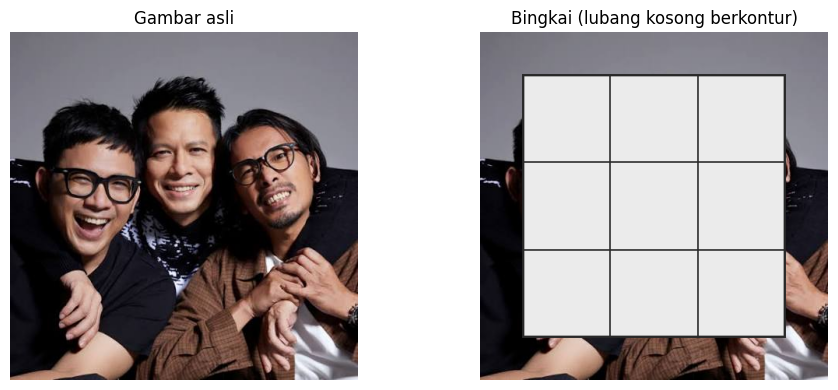

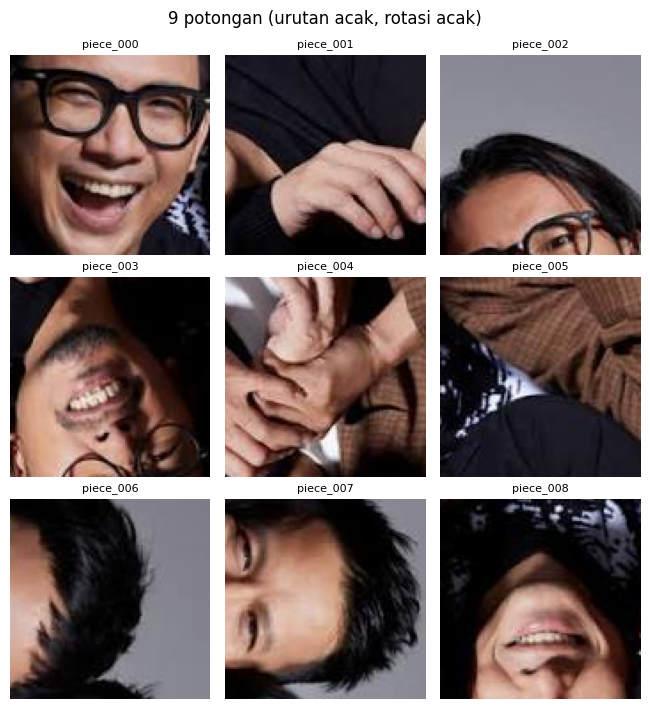

In [9]:
img = load_image(IMAGE_SOURCE)
print("Gambar masukan:", img.shape, "| tipe:", img.dtype)

frame, items, info, (top, left, s) = generate_puzzle(img, M, OUT_DIR, FRAME_BORDER, SHUFFLE, ROTATE, SEED)

print("Ukuran bingkai :", frame.shape, "(sama dengan gambar)")
print("Lubang bingkai :", s * M, "x", s * M, "px, di posisi (y, x) =", (top, left))
print("Jumlah potongan:", len(items), "| ukuran tiap potongan:", items[0]["piece"].shape)
print("Rotasi tiap potongan (x90 derajat):", [it["rot"] for it in items])
print("Berkas di", OUT_DIR, ":", len(os.listdir(OUT_DIR)), "berkas (1 bingkai + N potongan + info.json)")

# ---- Verifikasi: tempel potongan (setelah rotasi dibatalkan) ke bingkai, harus sama dengan gambar asli ----
with open(os.path.join(OUT_DIR, "info.json")) as f:
    meta = json.load(f)
h = meta["hole"]
rebuilt = np.array(Image.open(os.path.join(OUT_DIR, "frame.png")))
for p in meta["pieces"]:
    piece = rotate90(np.array(Image.open(os.path.join(OUT_DIR, p["file"]))), -p["rotation"])
    y, x = h["top"] + p["row"] * h["cell_size"], h["left"] + p["col"] * h["cell_size"]
    rebuilt[y:y + h["cell_size"], x:x + h["cell_size"]] = piece

assert meta["N"] == M * M == len(meta["pieces"])
assert frame.shape == img.shape                       # bingkai meniru ukuran gambar
assert all(it["piece"].shape[:2] == (s, s) for it in items)   # semua potongan pas dengan sel bingkai
assert np.array_equal(rebuilt, img)                   # bingkai + potongan = gambar asli, tanpa piksel hilang
print("Verifikasi OK: bingkai + potongan identik dengan gambar asli.")

# ---- Tampilan ----
plt.figure(figsize=(10, 4))
plt.subplot(1, 2, 1)
plt.imshow(img, cmap="gray" if img.ndim == 2 else None, vmin=0, vmax=255)
plt.title("Gambar asli")
plt.axis("off")
plt.subplot(1, 2, 2)
plt.imshow(frame, cmap="gray" if frame.ndim == 2 else None, vmin=0, vmax=255)
plt.title("Bingkai (lubang kosong berkontur)")
plt.axis("off")
plt.tight_layout()
plt.show()

cols = M
rows = math.ceil(len(items) / cols)
plt.figure(figsize=(2.2 * cols, 2.4 * rows))
for i, it in enumerate(items):
    plt.subplot(rows, cols, i + 1)
    plt.imshow(it["piece"], cmap="gray" if it["piece"].ndim == 2 else None, vmin=0, vmax=255)
    plt.title(f"piece_{i:03d}", fontsize=8)
    plt.axis("off")
plt.suptitle(f"{len(items)} potongan (urutan acak, rotasi acak)")
plt.tight_layout()
plt.show()

In [12]:
# ===== GUI Puzzle Generator (Tkinter) - versi perbaikan =====
# Cell ini HANYA berisi GUI. Jalankan dulu semua cell di atasnya (parameter, load_image, generate_puzzle, dst.).
# Perbaikan: proses di thread terpisah (jendela tidak freeze), progress bar, tombol "Buka folder output",
# klik thumbnail untuk memperbesar potongan, dan scroll mouse yang konsisten di Windows/Mac/Linux.
import queue
import subprocess
import sys
import threading
import tkinter as tk
from tkinter import ttk, filedialog, messagebox
from PIL import ImageTk


def _fit(w, h, max_w, max_h):
    """Ukuran (w, h) yang muat di kotak max_w x max_h dengan rasio tetap."""
    scale = min(max_w / w, max_h / h)
    return max(1, int(w * scale)), max(1, int(h * scale))


def open_folder(path):
    """Buka folder di file manager bawaan OS."""
    path = os.path.abspath(path)
    if sys.platform.startswith("win"):
        os.startfile(path)
    elif sys.platform == "darwin":
        subprocess.Popen(["open", path])
    else:
        subprocess.Popen(["xdg-open", path])


class PuzzleGeneratorApp(tk.Tk):
    PREVIEW = (460, 460)      # kotak maksimum pratinjau bingkai / gambar asli
    THUMB = 110               # sisi maksimum thumbnail potongan
    ZOOM = (600, 600)         # kotak maksimum jendela perbesaran potongan

    def __init__(self):
        super().__init__()
        self.title("Puzzle World - Puzzle Generator")
        self.geometry("1100x740")
        self.minsize(900, 600)
        self._photos = []             # simpan referensi PhotoImage agar tidak dihapus garbage collector
        self._queue = queue.Queue()   # hasil dari thread kerja -> thread utama (Tkinter)
        self._last_out_dir = None
        self._build_controls()
        self._build_preview()
        self.status.set("Isi sumber gambar, atur parameter, lalu klik Generate.")

    # ---------- panel kontrol (nilai awal diambil dari cell parameter) ----------
    def _build_controls(self):
        box = ttk.LabelFrame(self, text="Pengaturan", padding=10)
        box.pack(fill="x", padx=10, pady=(10, 5))

        ttk.Label(box, text="Gambar (path / URL):").grid(row=0, column=0, sticky="w")
        self.source = tk.StringVar(value=globals().get("IMAGE_SOURCE", ""))
        ttk.Entry(box, textvariable=self.source, width=70).grid(row=0, column=1, sticky="we", padx=5)
        ttk.Button(box, text="Pilih berkas...", command=self._pick_image).grid(row=0, column=2, padx=2)

        ttk.Label(box, text="Folder output:").grid(row=1, column=0, sticky="w", pady=(6, 0))
        self.out_dir = tk.StringVar(value=globals().get("OUT_DIR", "puzzle_output"))
        ttk.Entry(box, textvariable=self.out_dir, width=70).grid(row=1, column=1, sticky="we", padx=5, pady=(6, 0))
        ttk.Button(box, text="Pilih folder...", command=self._pick_folder).grid(row=1, column=2, padx=2, pady=(6, 0))

        opt = ttk.Frame(box)
        opt.grid(row=2, column=0, columnspan=3, sticky="w", pady=(10, 0))

        ttk.Label(opt, text="M (grid M x M):").pack(side="left")
        self.M = tk.IntVar(value=globals().get("M", 4))
        ttk.Spinbox(opt, from_=2, to=20, textvariable=self.M, width=5).pack(side="left", padx=(4, 16))

        ttk.Label(opt, text="Tebal bingkai (%):").pack(side="left")
        self.border = tk.IntVar(value=int(round(globals().get("FRAME_BORDER", 0.12) * 100)))
        ttk.Spinbox(opt, from_=2, to=40, textvariable=self.border, width=5).pack(side="left", padx=(4, 16))

        self.shuffle = tk.BooleanVar(value=globals().get("SHUFFLE", True))
        self.rotate = tk.BooleanVar(value=globals().get("ROTATE", True))
        ttk.Checkbutton(opt, text="Shuffle", variable=self.shuffle).pack(side="left", padx=4)
        ttk.Checkbutton(opt, text="Rotate", variable=self.rotate).pack(side="left", padx=(4, 16))

        ttk.Label(opt, text="Seed (kosong = acak):").pack(side="left")
        seed0 = globals().get("SEED", None)
        self.seed = tk.StringVar(value="" if seed0 is None else str(seed0))
        ttk.Entry(opt, textvariable=self.seed, width=8).pack(side="left", padx=(4, 16))

        self.btn = ttk.Button(opt, text="Generate", command=self._generate)
        self.btn.pack(side="left", padx=8)
        self.btn_open = ttk.Button(opt, text="Buka folder output", command=self._open_output, state="disabled")
        self.btn_open.pack(side="left", padx=4)

        self.progress = ttk.Progressbar(box, mode="indeterminate")
        self.progress.grid(row=3, column=0, columnspan=3, sticky="we", pady=(10, 0))

        box.columnconfigure(1, weight=1)

    # ---------- panel pratinjau ----------
    def _build_preview(self):
        paned = ttk.PanedWindow(self, orient="horizontal")
        paned.pack(fill="both", expand=True, padx=10, pady=5)

        left = ttk.Frame(paned)
        tabs = ttk.Notebook(left)
        tabs.pack(fill="both", expand=True)
        self.lbl_frame = ttk.Label(tabs, anchor="center")
        self.lbl_orig = ttk.Label(tabs, anchor="center")
        tabs.add(self.lbl_frame, text="Bingkai")
        tabs.add(self.lbl_orig, text="Gambar asli")
        paned.add(left, weight=1)

        right = ttk.LabelFrame(paned, text="Potongan (urutan acak, sudah dirotasi) - klik untuk memperbesar")
        self.canvas = tk.Canvas(right, highlightthickness=0)
        sb = ttk.Scrollbar(right, orient="vertical", command=self.canvas.yview)
        self.canvas.configure(yscrollcommand=sb.set)
        sb.pack(side="right", fill="y")
        self.canvas.pack(side="left", fill="both", expand=True)
        self.grid_frame = ttk.Frame(self.canvas)
        self.canvas.create_window((0, 0), window=self.grid_frame, anchor="nw")
        self.grid_frame.bind("<Configure>", lambda e: self.canvas.configure(scrollregion=self.canvas.bbox("all")))
        # delta berbeda tiap OS (Windows kelipatan 120, Mac kecil), jadi cukup pakai tandanya
        self.bind_all("<MouseWheel>", lambda e: self.canvas.yview_scroll(-1 if e.delta > 0 else 1, "units"))
        self.bind_all("<Button-4>", lambda e: self.canvas.yview_scroll(-1, "units"))   # scroll di Linux
        self.bind_all("<Button-5>", lambda e: self.canvas.yview_scroll(1, "units"))
        paned.add(right, weight=1)

        self.status = tk.StringVar()
        ttk.Label(self, textvariable=self.status, relief="sunken", anchor="w", padding=4).pack(fill="x", side="bottom")

    # ---------- aksi ----------
    def _pick_image(self):
        path = filedialog.askopenfilename(title="Pilih gambar",
                                          filetypes=[("Gambar", "*.png *.jpg *.jpeg *.bmp *.webp"), ("Semua berkas", "*.*")])
        if path:
            self.source.set(path)

    def _pick_folder(self):
        path = filedialog.askdirectory(title="Pilih folder output")
        if path:
            self.out_dir.set(path)

    def _open_output(self):
        if self._last_out_dir and os.path.isdir(self._last_out_dir):
            open_folder(self._last_out_dir)
        else:
            messagebox.showinfo("Folder belum ada", "Klik Generate dulu agar folder output terbentuk.")

    def _read_params(self):
        source = self.source.get().strip()
        if not source:
            raise ValueError("Isi dulu path atau URL gambar.")
        try:
            m = int(self.M.get())
            border = int(self.border.get()) / 100
            seed_txt = self.seed.get().strip()
            seed = int(seed_txt) if seed_txt else None
        except (tk.TclError, ValueError):
            raise ValueError("M, tebal bingkai, dan seed harus berupa bilangan bulat.")
        if m < 2:
            raise ValueError("M minimal 2.")
        return source, m, (self.out_dir.get().strip() or "puzzle_output"), border, self.shuffle.get(), self.rotate.get(), seed

    def _generate(self):
        try:
            params = self._read_params()
        except ValueError as e:
            messagebox.showwarning("Input tidak valid", str(e))
            return

        self.btn.state(["disabled"])
        self.progress.start(12)
        self.status.set("Memproses...")
        # Proses berat jalan di thread terpisah supaya jendela tetap responsif.
        threading.Thread(target=self._worker, args=params, daemon=True).start()
        self.after(100, self._poll)

    def _worker(self, source, m, out_dir, border, shuffle, rotate, seed):
        """Jalan di thread kerja: JANGAN menyentuh widget Tkinter di sini, cukup kirim hasil lewat queue."""
        try:
            img = load_image(source)                                                    # fungsi dari cell di atas
            frame, items, info, hole = generate_puzzle(img, m, out_dir, border, shuffle, rotate, seed)
            self._queue.put(("ok", img, frame, items, out_dir))
        except Exception as e:                  # URL salah, berkas rusak, M terlalu besar, dll.
            self._queue.put(("err", e))

    def _poll(self):
        """Cek hasil dari thread kerja tiap 100 ms (jalan di thread utama)."""
        try:
            msg = self._queue.get_nowait()
        except queue.Empty:
            self.after(100, self._poll)
            return

        self.progress.stop()
        self.btn.state(["!disabled"])
        if msg[0] == "err":
            e = msg[1]
            self.status.set("Gagal.")
            messagebox.showerror("Gagal membuat puzzle", f"{type(e).__name__}: {e}")
            return

        _, img, frame, items, out_dir = msg
        self._last_out_dir = out_dir
        self.btn_open.state(["!disabled"])
        self._show(img, frame, items)
        self.status.set(f"Selesai: 1 bingkai + {len(items)} potongan disimpan di '{out_dir}'")

    # ---------- tampilan ----------
    def _show(self, img, frame, items):
        self._photos = []
        for arr, lbl in ((frame, self.lbl_frame), (img, self.lbl_orig)):
            pil = Image.fromarray(arr)
            pil = pil.resize(_fit(pil.width, pil.height, *self.PREVIEW), Image.LANCZOS)
            ph = ImageTk.PhotoImage(pil)
            self._photos.append(ph)
            lbl.configure(image=ph)

        for w in self.grid_frame.winfo_children():
            w.destroy()
        cols = max(1, min(4, int(math.sqrt(len(items)))))
        for i, it in enumerate(items):
            pil = Image.fromarray(it["piece"])
            pil = pil.resize(_fit(pil.width, pil.height, self.THUMB, self.THUMB), Image.NEAREST)
            ph = ImageTk.PhotoImage(pil)
            self._photos.append(ph)
            cell = ttk.Frame(self.grid_frame, padding=3)
            cell.grid(row=i // cols, column=i % cols)
            lbl = ttk.Label(cell, image=ph, cursor="hand2")
            lbl.pack()
            lbl.bind("<Button-1>", lambda e, arr=it["piece"], n=i: self._zoom(arr, n))
            ttk.Label(cell, text=f"piece_{i:03d}", font=("TkDefaultFont", 8)).pack()
        self.canvas.yview_moveto(0)

    def _zoom(self, arr, index):
        """Buka jendela kecil berisi potongan dalam ukuran lebih besar (klik atau Esc untuk menutup)."""
        pil = Image.fromarray(arr)
        h, w = arr.shape[:2]
        pil = pil.resize(_fit(w, h, *self.ZOOM), Image.NEAREST)
        win = tk.Toplevel(self)
        win.title(f"piece_{index:03d} - {w} x {h} px")
        win.photo = ImageTk.PhotoImage(pil)       # referensi disimpan di jendela itu sendiri
        lbl = ttk.Label(win, image=win.photo)
        lbl.pack(padx=8, pady=8)
        lbl.bind("<Button-1>", lambda e: win.destroy())
        win.bind("<Escape>", lambda e: win.destroy())
        win.focus_set()


def launch_gui():
    """Buka jendela GUI. Cell berjalan sampai jendela ditutup."""
    app = PuzzleGeneratorApp()
    app.lift()
    app.attributes("-topmost", True)                        # munculkan di depan (sering tersembunyi di balik VS Code)
    app.after(400, lambda: app.attributes("-topmost", False))
    app.mainloop()


launch_gui()